<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/08_Phishing_Detection/HybridQNN_PhishingURL_Gupta2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid QNN for phishing-URL detection: Gupta et al. (2025) step by step

This notebook re-implements, runs and checks the method of

> Brij B. Gupta, Shin-Hung Pan, Akshat Gaurav, Varsha Arya, Razaz Waheeb Attar, Amal Hassan Alhazmi, Ahmed Alhomoud and Kwok Tai Chui,
> "Phishing threat mitigation in E-commerce using a quantum-enhanced hybrid AI framework",
> *Scientific Reports* 15, 42282 (2025). DOI 10.1038/s41598-025-27515-7

The paper's code is announced on Zenodo (DOI 10.5281/zenodo.17364368); this notebook was written from the paper text alone (Eqs. 1-11, Tables 1-2, Figs. 1-10) and does not copy that code.

**What the notebook does.** It downloads the UCI *Phishing Websites* data set (11,055 URLs, 30 hand-crafted features), splits it 80/20 as the paper's confusion matrix implies (2,211 test URLs) and builds the paper's hybrid network: a classical encoder (30 -> 2 numbers, ReLU) -> a **2-qubit parametrised circuit** (`RY` angle embedding, trainable `RY-RZ-RY` blocks, circular CNOTs, Pauli-Z read-out) -> two dense ReLU layers -> output layer. The circuit is simulated exactly and trained end to end with PyTorch (Adam, learning rate 0.01, batch size 32, cross-entropy, as in the paper's Table 1). The notebook then re-draws the paper's Figs. 2-10 (class distribution, Bloch vectors, expectation trajectory and histogram, classification report, confusion matrix, ROC, loss comparison with GRU / LSTM / RNN, metrics against parameter count), compares every checkable number with the paper, trains the same network **without** the quantum layer, and trains three standard classical classifiers on the identical 30 inputs.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs pinned versions of PennyLane and Qiskit (Qiskit is only used to cross-check the drawn circuit); if Colab asks you to restart the session, do so and run all again. No GPU, no IBM Quantum account and no Hugging Face token are needed (the data set is public on the UCI repository, with an OpenML mirror as fallback). If you ever swap in a gated Hugging Face data set, put your own token in Colab *Secrets* under the name `HF_TOKEN`; the notebook never stores or prints it.

**Runtime.** `FAST_MODE = True` (2,500 training URLs, 8 epochs, one seed) takes a few minutes. `FAST_MODE = False` is the full run (8,844 training URLs, the paper's 50 epochs, batch size 32, three seeds); the quantum layer is simulated with a hand-written exact 2-qubit state-vector routine that is checked against the PennyLane QNode, so the full run stays on the order of tens of minutes on a laptop CPU.

**What you get at the end.** The data-set plots, the drawn 2-qubit circuit with its qubit / depth / parameter counts, Bloch vectors, Pauli-Z expectation trajectory and histogram, the classification report, confusion matrix and ROC curve, the quantum-vs-no-quantum ablation, the comparison with GRU / LSTM / RNN, classical baselines, and a table that puts the paper's numbers next to ours with a verdict for each.

## The paper in one page

**Problem.** Decide whether a website is *phishing* or *legitimate* from 30 hand-crafted URL / domain / page features (e-commerce setting).

**Decision.** Binary classification of a pre-computed feature vector `x in R^30`.

**Method (Section "Proposed work", Eqs. 1-11, Fig. 1, Table 1).**
1. *Classical encoder* `h1 = ReLU(W1 x + b1)`, `h1 in R^{n_q}`, one number per qubit (Eq. 2).
2. *Angle embedding* of every `h1_i` with `RY` on its own qubit (Eqs. 3-4), `n_q = 2`.
3. *Strongly entangling layers*: `L` layers; per layer and qubit the trainable rotations `RY(t1) RZ(t2) RY(t3)` plus circular CNOTs; `theta in R^{L x n_q x 3}` (Eqs. 5-6).
4. *Measurement*: `z_j = <Z_j>` for both qubits (Eqs. 7-8).
5. *Classical head*: `h2 = ReLU(W2 z + b2)`, `h3 = ReLU(W3 h2 + b3)`, output `sigmoid(w4^T h3 + b4)` (Eqs. 9-11). Table 1 states Adam, learning rate 1e-2, batch 32, 50 epochs, cross-entropy loss, PennyLane simulator.

**Data.** UCI "Phishing Websites" (Mohammad and McCluskey; DOI 10.24432/C51W2X): 11,055 URLs, 30 features coded -1 / 0 / 1.

**Claims.**

| Claim | Where | Value |
|---|---|---|
| Accuracy | Abstract, Contributions, Conclusion | 97.3 % |
| Accuracy | Fig. 6 text ("Model performance") | 93 % (the confusion matrix gives 2,050 / 2,211 = 92.7 %) |
| Per-class F1 | Fig. 6 | 0.91 for class 0 ("Safe"), 0.94 for class 1 ("Phishing"); macro average 0.93 |
| Confusion matrix (2,211 test URLs) | Fig. 7 | 858 class-0 correct, 98 class-0 predicted as class 1, 63 class-1 predicted as class 0, 1,192 class-1 correct |
| AUC | Fig. 8 | 0.9768 for both classes |
| Parameter efficiency | Abstract, Fig. 10 | fewest trainable parameters among proposed model, GRU, LSTM, RNN |
| Convergence | Fig. 9 | lower and faster-falling training loss than GRU, LSTM, RNN |
| Best metrics | Fig. 10 | highest accuracy / precision / F1 of the four models |
| Quantum read-out | Figs. 4-5 | qubit 0: `<Z>` concentrated near +1; qubit 1: broad, symmetric spread incl. values near -1 |
| Qubits | Table 1 | 2 |

### What follows the paper and what had to be chosen

The paper does not give most hyper-parameters. Every choice below is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data set | UCI Phishing Websites, 11,055 URLs, 30 features | same (UCI id 327 via `ucimlrepo`; OpenML id 4534 as mirror) |
| Split | not stated; Fig. 7 sums to 2,211 = 20 % of 11,055 | stratified 80 / 20, `random_state=SEED`; 10 % of the training part held out for choosing the best epoch |
| Preprocessing | not described | none (features already -1 / 0 / 1); label phishing = 1 |
| Encoder | `ReLU(W1 x + b1)`, 30 -> `n_q` | one linear layer 30 -> 2 with ReLU |
| Qubits / embedding | 2 qubits, `RY` angle embedding | same; the ReLU output is used directly as the `RY` angle |
| Entangling layers `L` | "L layers", unspecified | `L = 2` blocks of `RY(t1) RZ(t2) RY(t3)` on each qubit, followed by the circular CNOT pair `CNOT(0,1) CNOT(1,0)` |
| Read-out | `<Z0>`, `<Z1>` | same, exact expectation values (no shot noise) |
| Head | 2 dense layers + ReLU, sigmoid output | 2 -> 16 -> 8 (ReLU) -> 2 logits with cross-entropy (equivalent to a sigmoid on one logit) |
| Optimiser | Adam, lr 1e-2, batch 32, 50 epochs, cross-entropy | same; the epoch with the lowest validation loss is kept (CHOICE) |
| Simulation | PennyLane | PennyLane QNode for drawing and checking; hand-written exact 2-qubit state-vector for training (asserted equal to the QNode) |
| GRU / LSTM / RNN baselines | architectures not given | one recurrent layer (hidden 32) over the 30 features read as a sequence of length 30, then a linear output; same optimiser and budget |
| Seeds | not stated | full run: 3 seeds for the hybrid network, the no-quantum ablation and the classical baselines, 1 seed for GRU / LSTM / RNN; FAST: 1 seed; mean +- std |
| Extra baselines | none | same network without the circuit, Random Forest, SVC (RBF), logistic regression, all on the same 30 inputs |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and torch.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" "qiskit==2.5.2" pylatexenc ucimlrepo
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")

PennyLane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE   = False          # True: class demo in a few minutes. False: full run (50 epochs, 3 seeds, full training set).
SEED        = 42              # master seed (data split, weights, shuffling)
N_QUBITS    = 2               # paper: 2-qubit circuit (Table 1)
N_LAYERS    = 2               # CHOICE: number of strongly-entangling blocks L (paper: "L layers", unspecified)
HEAD_1      = 16              # CHOICE: width of the first post-quantum dense layer (Eq. 9)
HEAD_2      = 8               # CHOICE: width of the second post-quantum dense layer (Eq. 10)
RNN_HIDDEN  = 32              # CHOICE: hidden size of the GRU / LSTM / RNN comparison models
TEST_SIZE   = 0.20            # CHOICE: 20 % test (Fig. 7 sums to 2,211 = 20 % of 11,055)
VAL_SIZE    = 0.10            # CHOICE: share of the training part used to pick the best epoch (never the test set)
BATCH_SIZE  = 32              # paper, Table 1
LR          = 1e-2            # paper, Table 1 (Adam)
EPOCHS      = 8 if FAST_MODE else 50        # paper: 50 epochs (full run); FAST_MODE: 8
SEEDS       = [SEED] if FAST_MODE else [SEED, SEED + 1, SEED + 2]   # repeated runs for mean +- std (hybrid, no-quantum ablation, classical baselines)
SEQ_SEEDS   = [SEED]          # CHOICE: GRU / LSTM / RNN are 3-10x slower to train on a CPU, so they run on the first seed only
TRAIN_CAP   = 2500 if FAST_MODE else None   # FAST_MODE: use at most this many training URLs
DATA_DIR    = "data_QC181"    # downloads are cached here
IBM_TOKEN   = ""              # not used: the paper's circuit is simulated exactly; no hardware run
print(dict(FAST_MODE=FAST_MODE, EPOCHS=EPOCHS, SEEDS=SEEDS, TRAIN_CAP=TRAIN_CAP, BATCH_SIZE=BATCH_SIZE, LR=LR))

{'FAST_MODE': False, 'EPOCHS': 50, 'SEEDS': [42, 43, 44], 'TRAIN_CAP': None, 'BATCH_SIZE': 32, 'LR': 0.01}


In [3]:
import os, time, copy, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import pennylane as qml
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score, roc_curve,
                             confusion_matrix, f1_score)
from IPython.display import display

# Hugging Face token (only needed if a gated data set is ever used; this notebook's data are public).
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

warnings.filterwarnings("ignore", category=UserWarning)
torch.set_default_dtype(torch.float64)       # exact simulation: keep complex128 amplitudes
torch.set_num_threads(1)                      # tiny tensors: one thread is fastest (and kind to shared machines)
DATA_DIR = Path(DATA_DIR); DATA_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

set_seed(SEED)
rng = np.random.default_rng(SEED)
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__)

numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1


## 1. Data: the UCI Phishing Websites set

Mohammad and McCluskey's data set has one row per website. The 30 features are hand-crafted checks of the URL and the page (IP address instead of domain name, URL length, `@` symbol, SSL certificate state, domain age, traffic rank, ... see the paper's Table 2), each coded `-1` (looks like phishing), `0` (suspicious) or `1` (looks legitimate). The label `Result` is `-1` for phishing and `1` for a legitimate site. We recode it to `1 = phishing` (the attack is the positive class).

In [4]:
def load_uci_phishing():
    csv = DATA_DIR / "uci327_phishing_websites.csv"
    if csv.exists():
        return pd.read_csv(csv)
    try:
        from ucimlrepo import fetch_ucirepo               # UCI repository, dataset id 327
        ds = fetch_ucirepo(id=327)
        df = ds.data.features.copy()
        df["result"] = ds.data.targets.iloc[:, 0].values
        src = "UCI repository via ucimlrepo (id 327)"
    except Exception as e:                                # fallback: OpenML mirror of the same file
        print("ucimlrepo failed (", type(e).__name__, ") -> using the OpenML mirror")
        from sklearn.datasets import fetch_openml
        fr = fetch_openml(data_id=4534, as_frame=True, data_home=str(DATA_DIR)).frame
        fr.columns = [c.lower() for c in fr.columns]
        df = fr.apply(pd.to_numeric)
        src = "OpenML id 4534"
    df.to_csv(csv, index=False)
    print("downloaded from", src)
    return df

raw = load_uci_phishing()
raw.columns = [c.strip().lower() for c in raw.columns]
FEATURES = [c for c in raw.columns if c != "result"]
assert len(FEATURES) == 30 and set(raw["result"].unique()) == {-1, 1}
y_all = (raw["result"].values == -1).astype(int)             # 1 = phishing, 0 = legitimate (safe)
X_all = raw[FEATURES].values.astype(float)
print("rows x columns:", raw.shape, "| features:", len(FEATURES), "| missing values:", int(raw.isna().sum().sum()))
print("exact duplicate rows (features + label):", int(raw.duplicated().sum()))

rows x columns: (11055, 31) | features: 30 | missing values: 0
exact duplicate rows (features + label): 5206


Before any modelling we split the data. Everything that is *fitted* (the PCA used for plotting below, every network, the baselines) sees the training part only; a further 10 % of the training part (`val`) chooses the best training epoch.

In [5]:
idx = np.arange(len(y_all))
tr_idx, te_idx = train_test_split(idx, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
fit_idx, val_idx = train_test_split(tr_idx, test_size=VAL_SIZE, stratify=y_all[tr_idx], random_state=SEED)
if TRAIN_CAP is not None and len(fit_idx) > TRAIN_CAP:                      # FAST_MODE only
    fit_idx, _ = train_test_split(fit_idx, train_size=TRAIN_CAP, stratify=y_all[fit_idx], random_state=SEED)
X_fit, y_fit = X_all[fit_idx], y_all[fit_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]
X_te,  y_te  = X_all[te_idx],  y_all[te_idx]
X_tr,  y_tr  = X_all[tr_idx],  y_all[tr_idx]
print(f"fit {len(y_fit)} | val {len(y_val)} | test {len(y_te)}   (phishing share: "
      f"{y_fit.mean():.3f} / {y_val.mean():.3f} / {y_te.mean():.3f})")

fit 7959 | val 885 | test 2211   (phishing share: 0.443 / 0.443 / 0.443)


## Dataset Exploration and Visualisation

All plots below use the real URLs of the UCI data set and their ground-truth label; nothing is simulated. The data set is binary (phishing vs legitimate); it carries no finer attack families.

In [6]:
print("shape of the full data set:", raw.shape)
print("feature names:", FEATURES)
print("value domain per feature (first four):", {c: sorted(raw[c].unique().tolist()) for c in FEATURES[:4]}, "...")
print("\noriginal label values (column 'result'):")
print(raw["result"].value_counts().rename({-1: "-1 (phishing)", 1: " 1 (legitimate)"}))
print(f"phishing share = {y_all.mean():.3f}, legitimate share = {1 - y_all.mean():.3f}   (the paper's text says 55.7 % phishing / 44.3 % safe; see section 4)")
display(raw.head())

shape of the full data set: (11055, 31)
feature names: ['having_ip_address', 'url_length', 'shortining_service', 'having_at_symbol', 'double_slash_redirecting', 'prefix_suffix', 'having_sub_domain', 'sslfinal_state', 'domain_registration_length', 'favicon', 'port', 'https_token', 'request_url', 'url_of_anchor', 'links_in_tags', 'sfh', 'submitting_to_email', 'abnormal_url', 'redirect', 'on_mouseover', 'rightclick', 'popupwindow', 'iframe', 'age_of_domain', 'dnsrecord', 'web_traffic', 'page_rank', 'google_index', 'links_pointing_to_page', 'statistical_report']
value domain per feature (first four): {'having_ip_address': [-1, 1], 'url_length': [-1, 0, 1], 'shortining_service': [-1, 1], 'having_at_symbol': [-1, 1]} ...

original label values (column 'result'):
result
 1 (legitimate)    6157
-1 (phishing)      4898
Name: count, dtype: int64
phishing share = 0.443, legitimate share = 0.557   (the paper's text says 55.7 % phishing / 44.3 % safe; see section 4)


,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report,result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


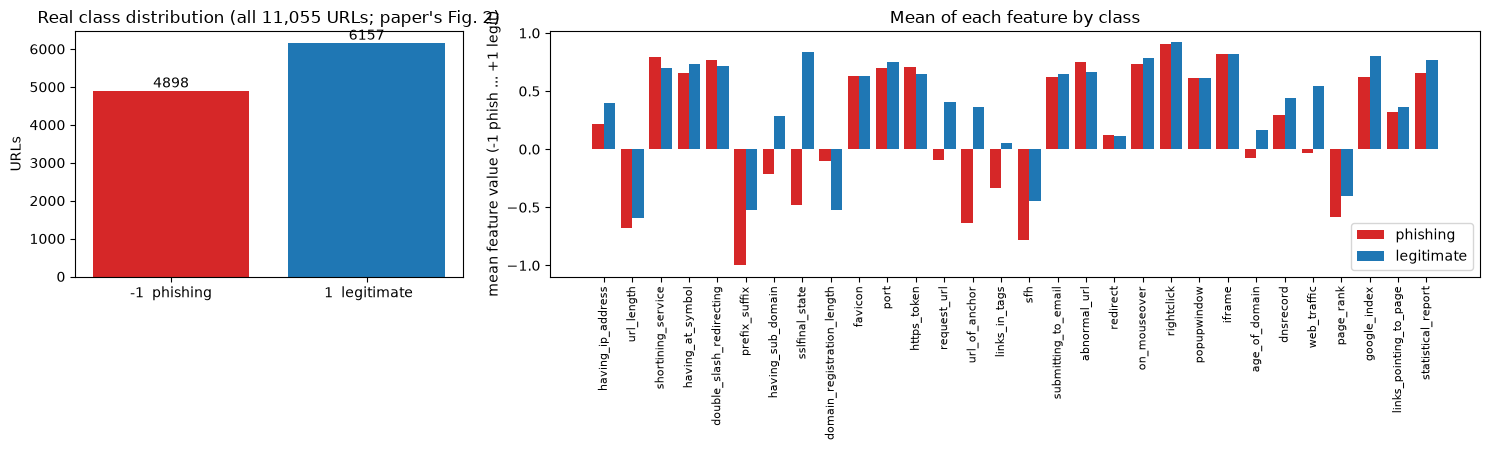

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw=dict(width_ratios=[1, 2.4]))
counts = raw["result"].value_counts().reindex([-1, 1])
bars = axes[0].bar(["-1  phishing", " 1  legitimate"], counts.values, color=["tab:red", "tab:blue"])
axes[0].bar_label(bars)
axes[0].set_ylabel("URLs"); axes[0].set_title("Real class distribution (all 11,055 URLs; paper's Fig. 2)")
means = pd.DataFrame(X_all, columns=FEATURES).groupby(y_all).mean()
xs = np.arange(len(FEATURES)); w = 0.4
axes[1].bar(xs - w/2, means.loc[1].values, w, color="tab:red", label="phishing")
axes[1].bar(xs + w/2, means.loc[0].values, w, color="tab:blue", label="legitimate")
axes[1].set_xticks(xs); axes[1].set_xticklabels(FEATURES, rotation=90, fontsize=8)
axes[1].set_ylabel("mean feature value (-1 phish ... +1 legit)"); axes[1].set_title("Mean of each feature by class"); axes[1].legend()
plt.tight_layout(); plt.show()

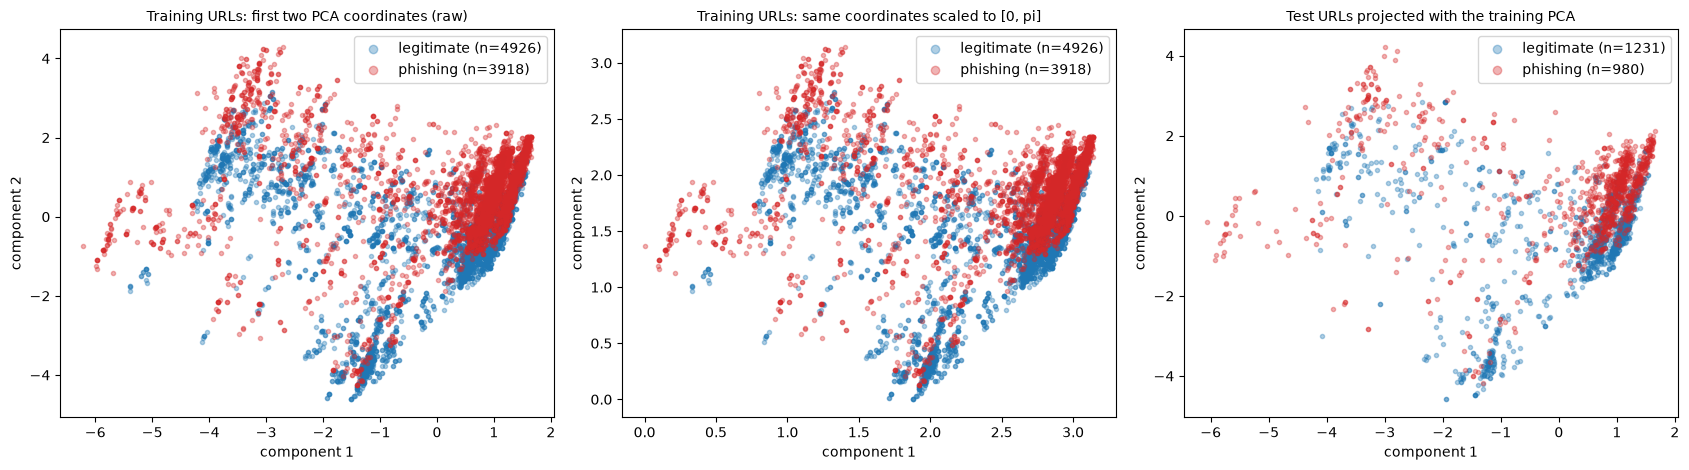

explained variance of the two PCA components: [0.154 0.117]
Features take only the values -1/0/1, so many URLs share the same coordinates (points overlap; alpha shows density).
The paper's circuit does NOT encode PCA angles: its two RY angles are the output of a learned 30 -> 2 encoder; they are plotted in section 7.


In [8]:
# 2-D view of the real URLs, coloured by ground truth. PCA is fitted on the TRAINING part only.
pca = PCA(n_components=2, random_state=SEED).fit(X_tr)
P_tr, P_te = pca.transform(X_tr), pca.transform(X_te)
ang = MinMaxScaler((0, np.pi)).fit(P_tr)                        # CHOICE: only for illustration, see below
A_tr, A_te = np.clip(ang.transform(P_tr), 0, np.pi), np.clip(ang.transform(P_te), 0, np.pi)
names = {1: "phishing", 0: "legitimate"}; cols = {1: "tab:red", 0: "tab:blue"}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (A, yy, ttl) in zip(axes, [(P_tr, y_tr, "Training URLs: first two PCA coordinates (raw)"),
                                  (A_tr, y_tr, "Training URLs: same coordinates scaled to [0, pi]"),
                                  (P_te, y_te, "Test URLs projected with the training PCA")]):
    for k in (0, 1):
        m = yy == k
        ax.scatter(A[m, 0], A[m, 1], s=9, alpha=0.35, c=cols[k], label=f"{names[k]} (n={m.sum()})")
    ax.set_title(ttl, fontsize=10); ax.set_xlabel("component 1"); ax.set_ylabel("component 2"); ax.legend(markerscale=2)
plt.tight_layout(); plt.show()
print("explained variance of the two PCA components:", np.round(pca.explained_variance_ratio_, 3))
print("Features take only the values -1/0/1, so many URLs share the same coordinates (points overlap; alpha shows density).")
print("The paper's circuit does NOT encode PCA angles: its two RY angles are the output of a learned 30 -> 2 encoder; they are plotted in section 7.")

## 2. Classical baselines on the identical 30 inputs

The paper reports no classical reference besides GRU / LSTM / RNN (section 6). We train three standard classifiers on exactly the data the hybrid network sees (`X_fit`, 30 features) and score them on the same test URLs. These numbers are what the quantum layer has to be compared with.

In [9]:
def report(y_true, p_phish, thr=0.5):
    # metrics in the paper's layout; phishing is the positive class (label 1)
    pred = (p_phish >= thr).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y_true, pred, labels=[1, 0], zero_division=0)
    sup = np.array([(y_true == 1).sum(), (y_true == 0).sum()])
    cm = confusion_matrix(y_true, pred, labels=[1, 0])          # rows actual (phish, legit), cols predicted (phish, legit)
    return dict(acc=accuracy_score(y_true, pred), auc=roc_auc_score(y_true, p_phish),
                p_ph=pr[0], r_ph=rc[0], f1_ph=f1[0], p_lg=pr[1], r_lg=rc[1], f1_lg=f1[1],
                macro_p=pr.mean(), macro_r=rc.mean(), macro_f1=f1.mean(), weighted_f1=np.average(f1, weights=sup),
                tp=cm[0, 0], fn=cm[0, 1], fp=cm[1, 0], tn=cm[1, 1], errors=int(cm[0, 1] + cm[1, 0]))

rows = []
baselines = {
    "RandomForest (300 trees)": lambda s: RandomForestClassifier(n_estimators=100 if FAST_MODE else 300, random_state=s, n_jobs=1),
    "SVC (RBF, C=1)":           lambda s: SVC(kernel="rbf", C=1.0, random_state=s),
    "LogisticRegression":       lambda s: LogisticRegression(max_iter=2000, random_state=s),
}
for name, make in baselines.items():
    for s in SEEDS:
        t0 = time.perf_counter(); mdl = make(s).fit(X_fit, y_fit)
        score = mdl.predict_proba(X_te)[:, 1] if hasattr(mdl, "predict_proba") else 1 / (1 + np.exp(-mdl.decision_function(X_te)))
        rows.append(dict(model=name, seed=s, seconds=time.perf_counter() - t0, **report(y_te, score)))
base_df = pd.DataFrame(rows)
show = ["acc", "weighted_f1", "macro_f1", "auc", "p_ph", "r_ph", "f1_ph", "errors", "seconds"]
display(base_df.groupby("model")[show].agg(["mean", "std"]).round(4))

acc         weighted_f1         macro_f1          \
                            mean     std        mean     std     mean     std   
model                                                                           
LogisticRegression        0.9285  0.0000      0.9284  0.0000   0.9273  0.0000   
RandomForest (300 trees)  0.9751  0.0009      0.9751  0.0009   0.9748  0.0009   
SVC (RBF, C=1)            0.9471  0.0000      0.9470  0.0000   0.9462  0.0000   

                             auc            p_ph           r_ph          \
                            mean     std    mean    std    mean     std   
model                                                                     
LogisticRegression        0.9785  0.0000  0.9363  0.000  0.9000  0.0000   
RandomForest (300 trees)  0.9965  0.0002  0.9803  0.001  0.9633  0.0018   
SVC (RBF, C=1)            0.9890  0.0000  0.9537  0.000  0.9255  0.0000   

                           f1_ph        errors       seconds          
                            mean    std   mean  std     mean     std  
model                                                                 
LogisticRegression        0.9178  0.000  158.0  0.0   0.5363  0.0160  
RandomForest (300 trees)  0.9717  0.001   55.0  2.0  10.8514  1.6031  
SVC (RBF, C=1)            0.9394  0.000  117.0  0.0  13.4029  0.6451

## Quantum Circuit Architecture

This is the circuit that is executed on every forward pass of the hybrid network (PennyLane `default.qubit`, exact state vector). For one URL it takes the 2 encoder outputs `h1 = (h1_0, h1_1)` as *data* angles and the `L x 2 x 3` trainable weights, and returns the two Pauli-Z expectations.

* **Angle embedding (Eqs. 3-4).** `RY(h1_i)` on qubit `i`, i.e. `RY(h1_0) (x) RY(h1_1) |00>`.
* **Strongly entangling blocks (Eqs. 5-6).** `L = 2` times: on every qubit `RY(t1) RZ(t2) RY(t3)`, then the circular CNOT pair `CNOT(0,1)`, `CNOT(1,0)`.
* **Measurement (Eqs. 7-8).** `<Z>` on each of the 2 qubits.

*Assumptions where the paper is silent:* the number of blocks `L`, the order of the gates inside a block (as listed in the paper: `RY-RZ-RY`), the exact CNOT pattern of the "circular" ring on 2 qubits (we use `CNOT(0,1)` then `CNOT(1,0)`), the initial weights (normal, std 0.1, so that the circuit starts near the identity), and that the ReLU output of the encoder is used directly as the `RY` angle (no rescaling).

Matplotlib is building the font cache; this may take a moment.


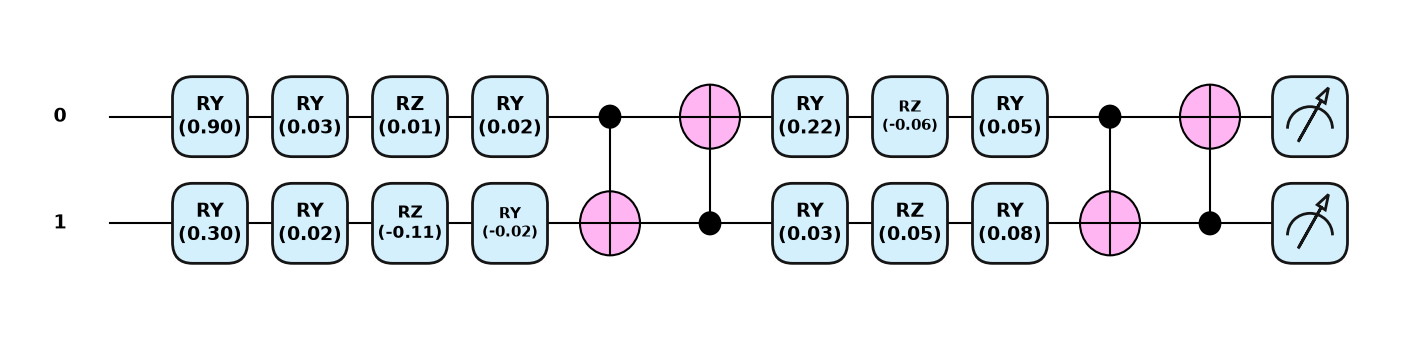

qubits: 2 | circuit depth: 11 | gates: {'RY': 10, 'RZ': 4, 'CNOT': 4}
trainable quantum parameters: 12 (= L x n_q x 3 = 2 x 2 x 3); data angles per URL: 2


In [10]:
dev = qml.device("default.qubit", wires=N_QUBITS)

def circuit_body(inputs, weights):
    # angle embedding, Eqs. (3)-(4): RY(h1_i) on qubit i
    for i in range(N_QUBITS):
        qml.RY(inputs[..., i], wires=i)
    # L strongly-entangling blocks, Eqs. (5)-(6): RY-RZ-RY on every qubit, then circular CNOTs   # CHOICE: gate order, CNOT order
    for l in range(N_LAYERS):
        for i in range(N_QUBITS):
            qml.RY(weights[l, i, 0], wires=i)
            qml.RZ(weights[l, i, 1], wires=i)
            qml.RY(weights[l, i, 2], wires=i)
        for i in range(N_QUBITS):
            qml.CNOT(wires=[i, (i + 1) % N_QUBITS])

@qml.qnode(dev, interface="torch", diff_method="backprop")
def qnode(inputs, weights):
    circuit_body(inputs, weights)
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

@qml.qnode(dev, interface="torch", diff_method="backprop")
def qnode_bloch(inputs, weights):                 # same circuit, X/Y/Z of every qubit (for the Bloch vectors)
    circuit_body(inputs, weights)
    return [qml.expval(op(i)) for i in range(N_QUBITS) for op in (qml.PauliX, qml.PauliY, qml.PauliZ)]

demo_inputs  = torch.tensor([0.9, 0.3])                                         # one example encoder output (for drawing only)
demo_weights = 0.1 * torch.randn(N_LAYERS, N_QUBITS, 3, generator=torch.Generator().manual_seed(SEED))
fig, ax = qml.draw_mpl(qnode, decimals=2, style="pennylane")(demo_inputs, demo_weights)
fig.set_size_inches(14, 3.2); plt.show()

specs = qml.specs(qnode)(demo_inputs, demo_weights)
res = specs["resources"] if isinstance(specs, dict) else specs.resources
print("qubits:", N_QUBITS, "| circuit depth:", res.depth, "| gates:", dict(res.gate_types))
print("trainable quantum parameters:", demo_weights.numel(), f"(= L x n_q x 3 = {N_LAYERS} x {N_QUBITS} x 3); data angles per URL: {N_QUBITS}")

**A fast exact simulator for training.** Calling the PennyLane QNode on every mini-batch costs about 60 ms per step on a CPU, which would make 50 epochs x 3 seeds very slow. For two qubits the whole trainable part of the circuit is one fixed `4 x 4` unitary `V(w)` (product of the single-qubit blocks and the CNOTs), and the embedded state is a product state, so the exact output is `z_j = <psi_in| V^dagger Z_j V |psi_in>`. The routine below computes this with a few tensor operations, is differentiable by PyTorch, and is **asserted equal to the QNode** (and, in the next cell, to an independent Qiskit statevector circuit) before it is used. It is the same mathematics, not an approximation.

In [11]:
def _ry(t):                      # 2x2 RY(t), complex
    c, s = torch.cos(t / 2), torch.sin(t / 2)
    return torch.stack([torch.stack([c, -s]), torch.stack([s, c])]).to(torch.complex128)
def _rz(t):
    e = torch.exp(-0.5j * t.to(torch.complex128)); z = torch.zeros_like(e)
    return torch.stack([torch.stack([e, z]), torch.stack([z, e.conj()])])
_I2 = torch.eye(2, dtype=torch.complex128)
_CX01 = torch.tensor([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=torch.complex128)   # control wire 0, target wire 1
_CX10 = torch.tensor([[1, 0, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0], [0, 1, 0, 0]], dtype=torch.complex128)   # control wire 1, target wire 0
assert N_QUBITS == 2, "the fast simulator is written for the paper's 2-qubit circuit"

def unitary_V(weights):
    V = torch.eye(4, dtype=torch.complex128)
    for l in range(N_LAYERS):
        U = []
        for i in range(2):
            U.append(_ry(weights[l, i, 2]) @ _rz(weights[l, i, 1]) @ _ry(weights[l, i, 0]))     # RY first, then RZ, then RY
        K = torch.kron(U[0], U[1])                      # wire 0 is the most significant bit, as in PennyLane
        V = _CX10 @ _CX01 @ K @ V
    return V

_PAULI = {"X": torch.tensor([[0, 1], [1, 0]], dtype=torch.complex128),
          "Y": torch.tensor([[0, -1j], [1j, 0]], dtype=torch.complex128),
          "Z": torch.tensor([[1, 0], [0, -1]], dtype=torch.complex128)}

def fast_out(h, weights, bloch=False):
    """Exact outputs of the circuit for a batch h of shape (B, 2): <Z0>, <Z1>  (or X,Y,Z of both qubits)."""
    c, s = torch.cos(h / 2), torch.sin(h / 2)                                   # RY(h_i)|0> = (cos, sin)
    psi = torch.stack([c[:, 0] * c[:, 1], c[:, 0] * s[:, 1], s[:, 0] * c[:, 1], s[:, 0] * s[:, 1]], dim=1).to(torch.complex128)
    out = psi @ unitary_V(weights).T                                             # final state, shape (B, 4)
    if not bloch:
        p = out.real ** 2 + out.imag ** 2
        return torch.stack([p @ torch.tensor([1., 1., -1., -1.]), p @ torch.tensor([1., -1., 1., -1.])], dim=-1)
    res = []
    for i in range(2):
        for P in "XYZ":
            O = torch.kron(_PAULI[P], _I2) if i == 0 else torch.kron(_I2, _PAULI[P])
            res.append((out.conj() * (out @ O.T)).sum(-1).real)
    return torch.stack(res, dim=-1)

g = torch.Generator().manual_seed(SEED)
for _ in range(20):                                                              # equivalence with the real PennyLane QNode
    hh = 3 * torch.rand(4, N_QUBITS, generator=g); ww = 0.8 * torch.randn(N_LAYERS, N_QUBITS, 3, generator=g)
    a = torch.stack(qnode(hh, ww), dim=-1).detach().numpy(); b = fast_out(hh, ww).detach().numpy()
    assert np.allclose(a, b, atol=1e-10), (a, b)
    a3 = torch.stack(qnode_bloch(hh, ww), dim=-1).detach().numpy(); b3 = fast_out(hh, ww, bloch=True).detach().numpy()
    assert np.allclose(a3, b3, atol=1e-10), (a3, b3)
print("fast_out == PennyLane QNode (<Z>, and <X>,<Y>,<Z> of both qubits) on 20 random batches, atol 1e-10.")

fast_out == PennyLane QNode (<Z>, and <X>,<Y>,<Z> of both qubits) on 20 random batches, atol 1e-10.


In [12]:
# Second, independent check: rebuild the same gate sequence in Qiskit and compare <Z_i> with the PennyLane QNode.
try:
    from qiskit import QuantumCircuit
    from qiskit.quantum_info import Statevector, Pauli
    def qiskit_z(h, w):
        qc = QuantumCircuit(N_QUBITS)
        for i in range(N_QUBITS):
            qc.ry(float(h[i]), i)
        for l in range(N_LAYERS):
            for i in range(N_QUBITS):
                qc.ry(float(w[l, i, 0]), i); qc.rz(float(w[l, i, 1]), i); qc.ry(float(w[l, i, 2]), i)
            for i in range(N_QUBITS):
                qc.cx(i, (i + 1) % N_QUBITS)
        sv = Statevector(qc)
        return np.array([sv.expectation_value(Pauli("I" * (N_QUBITS - 1 - i) + "Z" + "I" * i)).real for i in range(N_QUBITS)])
    g = torch.Generator().manual_seed(SEED)
    for _ in range(5):
        h = 3 * torch.rand(N_QUBITS, generator=g); w = 0.8 * torch.randn(N_LAYERS, N_QUBITS, 3, generator=g)
        a = torch.stack(qnode(h, w)).detach().numpy(); b = qiskit_z(h.numpy(), w.numpy())
        assert np.allclose(a, b, atol=1e-8), (a, b)
    print("PennyLane QNode and an independent Qiskit statevector circuit agree on 5 random inputs (atol 1e-8).")
except ImportError:
    print("Qiskit not installed: equivalence check skipped (the drawn circuit is the executed PennyLane QNode).")

PennyLane QNode and an independent Qiskit statevector circuit agree on 5 random inputs (atol 1e-8).


## 3. The hybrid network and its training

`HybridNet` is Eqs. 2-11 with the quantum layer switched on or off. With `use_quantum=False` the circuit is removed and the head sees the encoder output `h1` directly (an otherwise identical classical network with the same 2-number bottleneck): this is the ablation that tells us how much the 2 qubits contribute. Gradients flow from the loss through the exact simulator into the encoder weights and the circuit weights together.

The same cell also defines the GRU / LSTM / RNN comparison models of the paper's Figs. 9-10: one recurrent layer reading the 30 features as a sequence of length 30 (one number per step), followed by a linear output layer.

In [13]:
class HybridNet(nn.Module):
    def __init__(self, use_quantum=True):
        super().__init__()
        self.use_quantum = use_quantum
        self.enc = nn.Linear(30, N_QUBITS)                                          # Eq. (2): h1 = ReLU(W1 x + b1), h1 in R^{n_q}
        if use_quantum:
            self.qw = nn.Parameter(0.1 * torch.randn(N_LAYERS, N_QUBITS, 3))        # CHOICE: small normal initial circuit weights
        self.head = nn.Sequential(nn.Linear(N_QUBITS, HEAD_1), nn.ReLU(),         # Eq. (9)
                                  nn.Linear(HEAD_1, HEAD_2), nn.ReLU(),            # Eq. (10)
                                  nn.Linear(HEAD_2, 2))                            # Eq. (11), two logits + cross-entropy
    def encode(self, x):
        return torch.relu(self.enc(x))
    def features(self, x):
        h = self.encode(x)
        z = fast_out(h, self.qw) if self.use_quantum else h
        return h, z
    def forward(self, x):
        return self.head(self.features(x)[1])

class SeqNet(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.rnn = {"GRU": nn.GRU, "LSTM": nn.LSTM, "RNN": nn.RNN}[kind](1, RNN_HIDDEN, batch_first=True)
        self.out = nn.Linear(RNN_HIDDEN, 2)
    def forward(self, x):
        o, _ = self.rnn(x.unsqueeze(-1))               # (B, 30, 1) -> (B, 30, H)
        return self.out(o[:, -1])

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
set_seed(SEED)
m = HybridNet(True)
print(f"Hybrid QNN: {n_params(m)} trainable parameters (encoder {sum(p.numel() for p in m.enc.parameters())}, circuit {m.qw.numel()}, head {sum(p.numel() for p in m.head.parameters())})")
print(f"Same network without the circuit: {n_params(HybridNet(False))} trainable parameters")
for k in ("GRU", "LSTM", "RNN"):
    print(f"{k}: {n_params(SeqNet(k))} trainable parameters")

Hybrid QNN: 276 trainable parameters (encoder 62, circuit 12, head 202)
Same network without the circuit: 264 trainable parameters
GRU: 3426 trainable parameters
LSTM: 4546 trainable parameters
RNN: 1186 trainable parameters


In [14]:
def predict_proba(model, X, bs=1024):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(torch.softmax(model(torch.tensor(X[i:i + bs])), dim=-1)[:, 1].numpy())
    return np.concatenate(out)

Z_PROBE = torch.tensor(X_fit[:512])                        # fixed probe URLs for the <Z0> trajectory (paper's Fig. 4)

def train_one(make_model, label, seed):
    set_seed(seed)
    model = make_model()
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    lossf = nn.CrossEntropyLoss()
    Xf, yf = torch.tensor(X_fit), torch.tensor(y_fit)
    Xv, yv = torch.tensor(X_val), torch.tensor(y_val)
    gen = torch.Generator().manual_seed(seed)
    hist, best, best_state, best_ep, ztraj = [], np.inf, None, 1, []
    t0 = time.perf_counter()
    for ep in range(1, EPOCHS + 1):
        model.train(); perm = torch.randperm(len(Xf), generator=gen); run = 0.0
        for i in range(0, len(Xf), BATCH_SIZE):
            b = perm[i:i + BATCH_SIZE]
            opt.zero_grad(); loss = lossf(model(Xf[b]), yf[b]); loss.backward(); opt.step()
            run += loss.item() * len(b)
        model.eval()
        with torch.no_grad():
            lv = model(Xv); val_loss = lossf(lv, yv).item(); val_acc = (lv.argmax(1) == yv).double().mean().item()
            if hasattr(model, "features"):
                zz = model.features(Z_PROBE)[1]; ztraj.append(zz.mean(0).numpy().copy())
        hist.append(dict(epoch=ep, train_loss=run / len(Xf), val_loss=val_loss, val_acc=val_acc))
        if val_loss < best: best, best_state, best_ep = val_loss, copy.deepcopy(model.state_dict()), ep
        if ep == 1 or ep % 5 == 0 or ep == EPOCHS:
            print(f"  [{label} seed {seed}] epoch {ep:2d}/{EPOCHS}  train loss {hist[-1]['train_loss']:.4f}"
                  f"  val loss {val_loss:.4f}  val acc {val_acc:.4f}  ({time.perf_counter() - t0:.0f}s)")
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), best_ep, time.perf_counter() - t0, np.array(ztraj)

In [15]:
HY, NQ = "Hybrid QNN (2 qubits)", "Same network, no quantum layer"
variants = {HY: lambda: HybridNet(True), NQ: lambda: HybridNet(False),
            "GRU": lambda: SeqNet("GRU"), "LSTM": lambda: SeqNet("LSTM"), "RNN": lambda: SeqNet("RNN")}
runs = {}        # (variant, seed) -> dict(model, hist, best_epoch, seconds, p_test, ztraj)
net_rows = []
for s in SEEDS:
    for variant, mk in variants.items():
        if variant in ("GRU", "LSTM", "RNN") and s not in SEQ_SEEDS:
            continue
        model, hist, best_ep, secs, ztraj = train_one(mk, variant, s)
        t0 = time.perf_counter(); p = predict_proba(model, X_te); t_pred = time.perf_counter() - t0
        runs[(variant, s)] = dict(model=model, hist=hist, best_epoch=best_ep, seconds=secs, p_test=p, ztraj=ztraj)
        net_rows.append(dict(model=variant, seed=s, params=n_params(model), seconds=secs + t_pred, best_epoch=best_ep, **report(y_te, p)))
net_df = pd.DataFrame(net_rows)
display(net_df[["model", "seed", "params", "best_epoch", "acc", "weighted_f1", "auc", "errors", "seconds"]].round(4))

  [Hybrid QNN (2 qubits) seed 42] epoch  1/50  train loss 0.3290  val loss 0.1833  val acc 0.9311  (13s)


  [Hybrid QNN (2 qubits) seed 42] epoch  5/50  train loss 0.2065  val loss 0.1660  val acc 0.9458  (65s)


  [Hybrid QNN (2 qubits) seed 42] epoch 10/50  train loss 0.1926  val loss 0.1951  val acc 0.9299  (133s)


  [Hybrid QNN (2 qubits) seed 42] epoch 15/50  train loss 0.1910  val loss 0.1672  val acc 0.9345  (175s)


  [Hybrid QNN (2 qubits) seed 42] epoch 20/50  train loss 0.1935  val loss 0.1730  val acc 0.9435  (217s)


...

  [Same network, no quantum layer seed 44] epoch 35/50  train loss 0.1733  val loss 0.1533  val acc 0.9356  (83s)


  [Same network, no quantum layer seed 44] epoch 40/50  train loss 0.1699  val loss 0.1596  val acc 0.9424  (95s)


  [Same network, no quantum layer seed 44] epoch 45/50  train loss 0.1728  val loss 0.1553  val acc 0.9401  (107s)


  [Same network, no quantum layer seed 44] epoch 50/50  train loss 0.1746  val loss 0.1512  val acc 0.9446  (119s)


,model,seed,params,best_epoch,acc,weighted_f1,auc,errors,seconds
0,Hybrid QNN (2 qubits),42,276,44,0.9258,0.9258,0.9770,164,412.3903
1,"Same network, no quantum layer",42,264,50,0.9367,0.9366,0.9810,140,63.8607
2,GRU,42,3426,18,0.9607,0.9606,0.9929,87,474.9096
3,LSTM,42,4546,44,0.9579,0.9579,0.9937,93,463.0123
4,RNN,42,1186,1,0.7408,0.7365,0.7964,573,132.7097
5,Hybrid QNN (2 qubits),43,276,29,0.9258,0.9256,0.9768,164,246.5206
6,"Same network, no quantum layer",43,264,27,0.9313,0.9311,0.9806,152,55.0238
7,Hybrid QNN (2 qubits),44,276,18,0.9331,0.9329,0.9782,148,420.4459
8,"Same network, no quantum layer",44,264,49,0.9272,0.9269,0.9803,161,118.5637


## 4. Metrics, confusion matrix and ROC curve (the paper's Figs. 6, 7, 8)

The paper reports precision, recall and F1 per class (class 0 "Safe", class 1 "Phishing"), the macro and weighted averages, the confusion matrix and one ROC curve with AUC 0.9768. We reproduce the three displays for the first seed of the hybrid network; the tables average over all seeds.

**A note on the class names.** In the paper's confusion matrix, class 0 has 956 test URLs and class 1 has 1,255. The UCI file has 4,898 phishing and 6,157 legitimate sites, i.e. about 980 phishing and 1,231 legitimate in a 20 % test set. The paper's class 0 therefore matches the *phishing* class in size and its class 1 the *legitimate* class (its text also says 55.7 % phishing, which is the legitimate share of the file). We suspect the paper's labels are swapped relative to the UCI semantics; to compare like with like, the tables below put the **minority class (real phishing, n about 980) first**, matching the paper's "class 0", and the paper's "class 1" corresponds to our legitimate class. Accuracy, macro averages, AUC and error counts do not depend on this naming.

Classification report of the hybrid QNN, seed 42 (paper's Fig. 6)


,Precision,Recall,F1 score
real phishing (paper: class 0),0.9224,0.9092,0.9157
legitimate (paper: class 1),0.9285,0.9391,0.9338
Accuracy,NaN,NaN,0.9258
Macro avg,0.9254,0.9241,0.9247
Weighted avg,0.9258,0.9258,0.9258


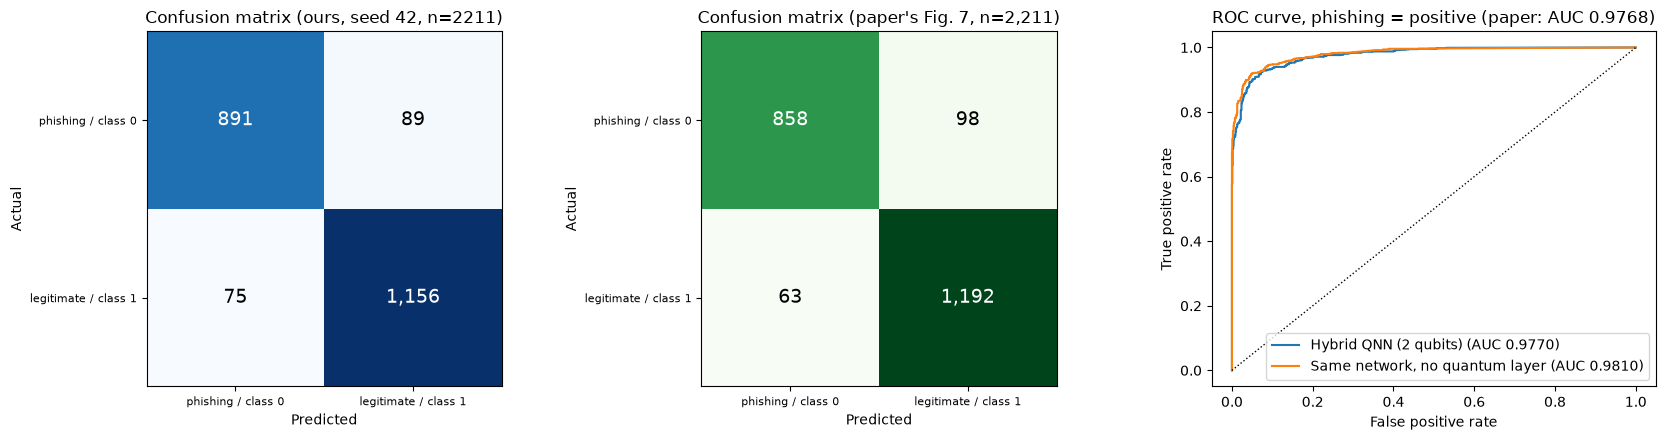

All trained networks, mean and std over seeds:


params          acc         weighted_f1  \
                                  mean  std    mean     std        mean   
model                                                                     
GRU                             3426.0  NaN  0.9607     NaN      0.9606   
Hybrid QNN (2 qubits)            276.0  0.0  0.9282  0.0042      0.9281   
LSTM                            4546.0  NaN  0.9579     NaN      0.9579   
RNN                             1186.0  NaN  0.7408     NaN      0.7365   
Same network, no quantum layer   264.0  0.0  0.9317  0.0048      0.9315   

                                       macro_f1             auc          \
                                   std     mean     std    mean     std   
model                                                                     
GRU                                NaN   0.9601     NaN  0.9929     NaN   
Hybrid QNN (2 qubits)           0.0042   0.9270  0.0042  0.9773  0.0008   
LSTM                               NaN   0.9573     NaN  0.9937     NaN   
RNN                                NaN   0.7306     NaN  0.7964     NaN   
Same network, no quantum layer  0.0048   0.9305  0.0050  0.9807  0.0003   

                                  errors            seconds           
                                    mean      std      mean      std  
model                                                                 
GRU                              87.0000      NaN  474.9096      NaN  
Hybrid QNN (2 qubits)           158.6667   9.2376  359.7856  98.1731  
LSTM                             93.0000      NaN  463.0123      NaN  
RNN                             573.0000      NaN  132.7097      NaN  
Same network, no quantum layer  151.0000  10.5357   79.1494  34.4186

Classical baselines for the same split:


acc         weighted_f1         macro_f1          \
                            mean     std        mean     std     mean     std   
model                                                                           
LogisticRegression        0.9285  0.0000      0.9284  0.0000   0.9273  0.0000   
RandomForest (300 trees)  0.9751  0.0009      0.9751  0.0009   0.9748  0.0009   
SVC (RBF, C=1)            0.9471  0.0000      0.9470  0.0000   0.9462  0.0000   

                             auc         errors       
                            mean     std   mean  std  
model                                                 
LogisticRegression        0.9785  0.0000  158.0  0.0  
RandomForest (300 trees)  0.9965  0.0002   55.0  2.0  
SVC (RBF, C=1)            0.9890  0.0000  117.0  0.0

In [16]:
s0 = SEEDS[0]; p0 = runs[(HY, s0)]["p_test"]; rep0 = report(y_te, p0)
n_ph, n_lg = int((y_te == 1).sum()), int((y_te == 0).sum())
cls = pd.DataFrame({"Precision": [rep0["p_ph"], rep0["p_lg"], np.nan, rep0["macro_p"]],
                    "Recall": [rep0["r_ph"], rep0["r_lg"], np.nan, rep0["macro_r"]],
                    "F1 score": [rep0["f1_ph"], rep0["f1_lg"], rep0["acc"], rep0["macro_f1"]]},
                   index=["real phishing (paper: class 0)", "legitimate (paper: class 1)", "Accuracy", "Macro avg"])
cls.loc["Weighted avg"] = [np.average([rep0["p_ph"], rep0["p_lg"]], weights=[n_ph, n_lg]),
                           np.average([rep0["r_ph"], rep0["r_lg"]], weights=[n_ph, n_lg]), rep0["weighted_f1"]]
print(f"Classification report of the hybrid QNN, seed {s0} (paper's Fig. 6)"); display(cls.round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
cm = np.array([[rep0["tp"], rep0["fn"]], [rep0["fp"], rep0["tn"]]])
paper_cm = np.array([[858, 98], [63, 1192]])
labs = ["phishing / class 0", "legitimate / class 1"]
for ax, M, ttl, cmap, thr in ((axes[0], cm, f"Confusion matrix (ours, seed {s0}, n={len(y_te)})", "Blues", cm.max() / 2),
                              (axes[1], paper_cm, "Confusion matrix (paper's Fig. 7, n=2,211)", "Greens", 600)):
    ax.imshow(M, cmap=cmap)
    for i in range(2):
        for j in range(2): ax.text(j, i, f"{M[i, j]:,}", ha="center", va="center", color="white" if M[i, j] > thr else "black", fontsize=14)
    ax.set_xticks([0, 1]); ax.set_xticklabels(labs, fontsize=8); ax.set_yticks([0, 1]); ax.set_yticklabels(labs, fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(ttl)
for (v, s), r in runs.items():
    if s == s0 and v in (HY, NQ):
        fpr, tpr, _ = roc_curve(y_te, r["p_test"])
        axes[2].plot(fpr, tpr, label=f"{v} (AUC {roc_auc_score(y_te, r['p_test']):.4f})")
axes[2].plot([0, 1], [0, 1], "k:", lw=1); axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate")
axes[2].set_title("ROC curve, phishing = positive (paper: AUC 0.9768)"); axes[2].legend(loc="lower right")
plt.tight_layout(); plt.show()

summ = net_df.groupby("model")[["params", "acc", "weighted_f1", "macro_f1", "auc", "errors", "seconds"]].agg(["mean", "std"]).round(4)
print("All trained networks, mean and std over seeds:"); display(summ)
print("Classical baselines for the same split:"); display(base_df.groupby("model")[["acc", "weighted_f1", "macro_f1", "auc", "errors"]].agg(["mean", "std"]).round(4))

## 5. Inside the quantum layer (the paper's Figs. 3, 4, 5)

* **Bloch vectors (Fig. 3).** Because the CNOTs entangle the two qubits, the reduced state of each qubit is generally *mixed* and its Bloch vector lies inside the sphere. For real training and test URLs we compute `(<X_i>, <Y_i>, <Z_i>)` from the same circuit; points are coloured by ground truth, the black arrow is the mean vector.
* **Expectation trajectory (Fig. 4).** Mean `<Z_0>` over a fixed probe of 512 training URLs after every epoch.
* **Histogram (Fig. 5).** Distribution of `<Z_0>` and `<Z_1>` over all test URLs after training.

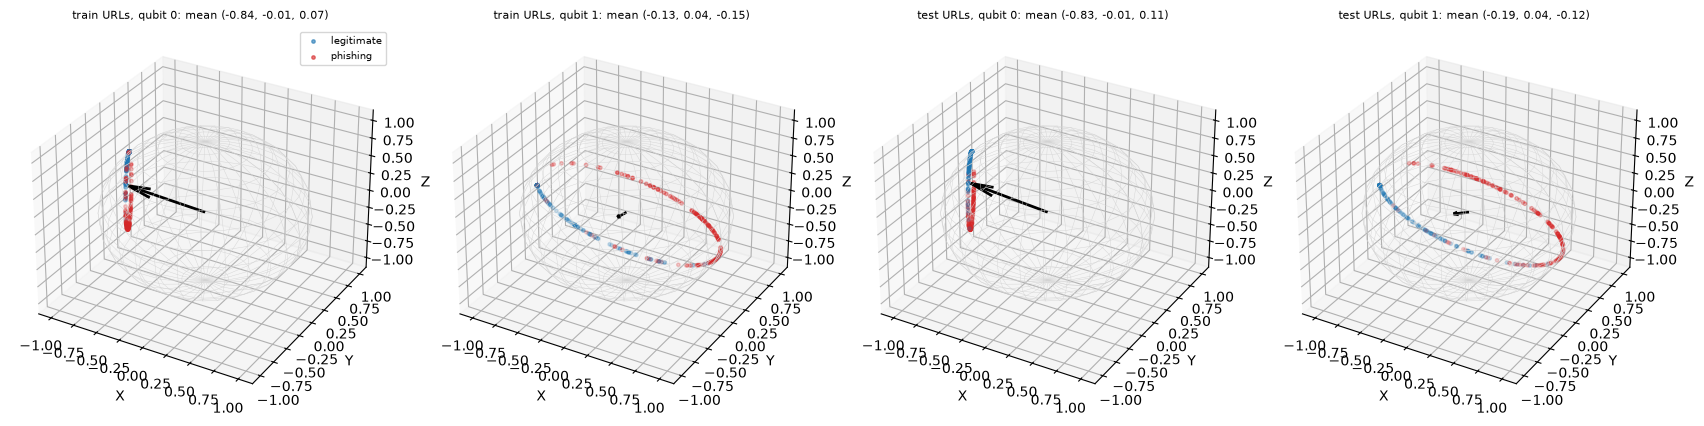

mean length of the Bloch vector per qubit on test URLs (1 = pure, <1 = entangled with the other qubit): [0.937 0.937]


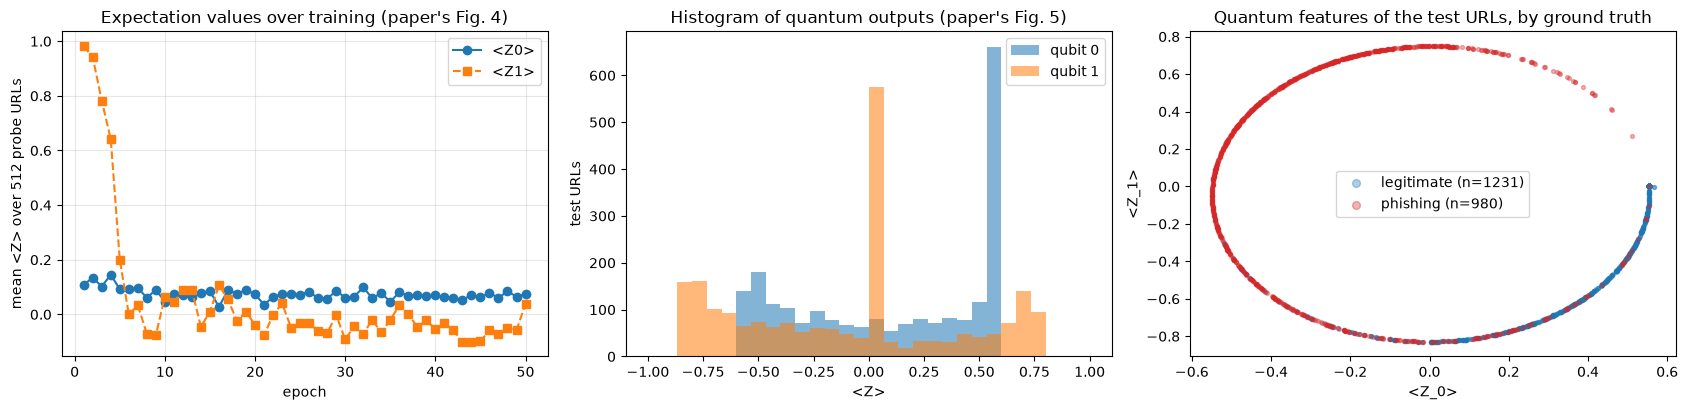

mean <Z_i> over test URLs: [ 0.103 -0.106] | median: [0.186 0.001] | std: [0.417 0.49 ]
trained circuit weights, range: [-1.748, 1.456]


In [17]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
mdl = runs[(HY, s0)]["model"]
with torch.no_grad():
    H_tr = mdl.encode(torch.tensor(X_tr)); H_te = mdl.encode(torch.tensor(X_te))
    B_tr = fast_out(H_tr, mdl.qw, bloch=True).numpy().reshape(len(X_tr), 2, 3)
    B_te = fast_out(H_te, mdl.qw, bloch=True).numpy().reshape(len(X_te), 2, 3)
sel_rng = np.random.default_rng(SEED)
sel_tr = sel_rng.choice(len(X_tr), size=300, replace=False); sel_te = sel_rng.choice(len(X_te), size=min(300, len(X_te)), replace=False)
u, v = np.mgrid[0:2 * np.pi:30j, 0:np.pi:15j]
fig = plt.figure(figsize=(17, 4.6))
panels = [("train", B_tr[sel_tr], y_tr[sel_tr], 0), ("train", B_tr[sel_tr], y_tr[sel_tr], 1),
          ("test", B_te[sel_te], y_te[sel_te], 0), ("test", B_te[sel_te], y_te[sel_te], 1)]
for k, (split, Bs, ys, q) in enumerate(panels):
    ax = fig.add_subplot(1, 4, k + 1, projection="3d")
    ax.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v), color="lightgray", lw=0.3)
    for c in (0, 1):
        mm = ys == c
        ax.scatter(Bs[mm, q, 0], Bs[mm, q, 1], Bs[mm, q, 2], s=6, c=cols[c], alpha=0.6, label=names[c])
    mb = Bs[:, q, :].mean(0); ax.quiver(0, 0, 0, *mb, color="k", lw=2)
    ax.set_title(f"{split} URLs, qubit {q}: mean ({mb[0]:.2f}, {mb[1]:.2f}, {mb[2]:.2f})", fontsize=8); ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
    if k == 0: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("mean length of the Bloch vector per qubit on test URLs (1 = pure, <1 = entangled with the other qubit):", np.round(np.linalg.norm(B_te, axis=2).mean(0), 3))

zt = runs[(HY, s0)]["ztraj"]; Z = B_te[:, :, 2]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].plot(np.arange(1, len(zt) + 1), zt[:, 0], "o-", label="<Z0>"); axes[0].plot(np.arange(1, len(zt) + 1), zt[:, 1], "s--", label="<Z1>")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("mean <Z> over 512 probe URLs"); axes[0].set_title("Expectation values over training (paper's Fig. 4)"); axes[0].legend(); axes[0].grid(alpha=0.3)
for q in range(2):
    axes[1].hist(Z[:, q], bins=30, range=(-1, 1), alpha=0.55, label=f"qubit {q}")
axes[1].set_xlabel("<Z>"); axes[1].set_ylabel("test URLs"); axes[1].set_title("Histogram of quantum outputs (paper's Fig. 5)"); axes[1].legend()
for c in (0, 1):
    mm = y_te == c; axes[2].scatter(Z[mm, 0], Z[mm, 1], s=8, alpha=0.35, c=cols[c], label=f"{names[c]} (n={mm.sum()})")
axes[2].set_xlabel("<Z_0>"); axes[2].set_ylabel("<Z_1>"); axes[2].set_title("Quantum features of the test URLs, by ground truth"); axes[2].legend(markerscale=2)
plt.tight_layout(); plt.show()
print("mean <Z_i> over test URLs:", np.round(Z.mean(0), 3), "| median:", np.round(np.median(Z, 0), 3), "| std:", np.round(Z.std(0), 3))
print("trained circuit weights, range: [%.3f, %.3f]" % (mdl.qw.min().item(), mdl.qw.max().item()))

## 6. Learned encoder angles and the paper's loss comparison (Figs. 9 and 10)

First, the real test URLs in the two learned `RY` angles `(h1_0, h1_1)` that actually enter the circuit, coloured by ground truth. Then the paper's convergence figure (training loss per epoch for the hybrid network against GRU, LSTM and RNN; Fig. 9) and its metrics-versus-parameter-count comparison (Fig. 10; the paper draws 3-D surfaces, we draw plain bars and a scatter of accuracy against parameter count).

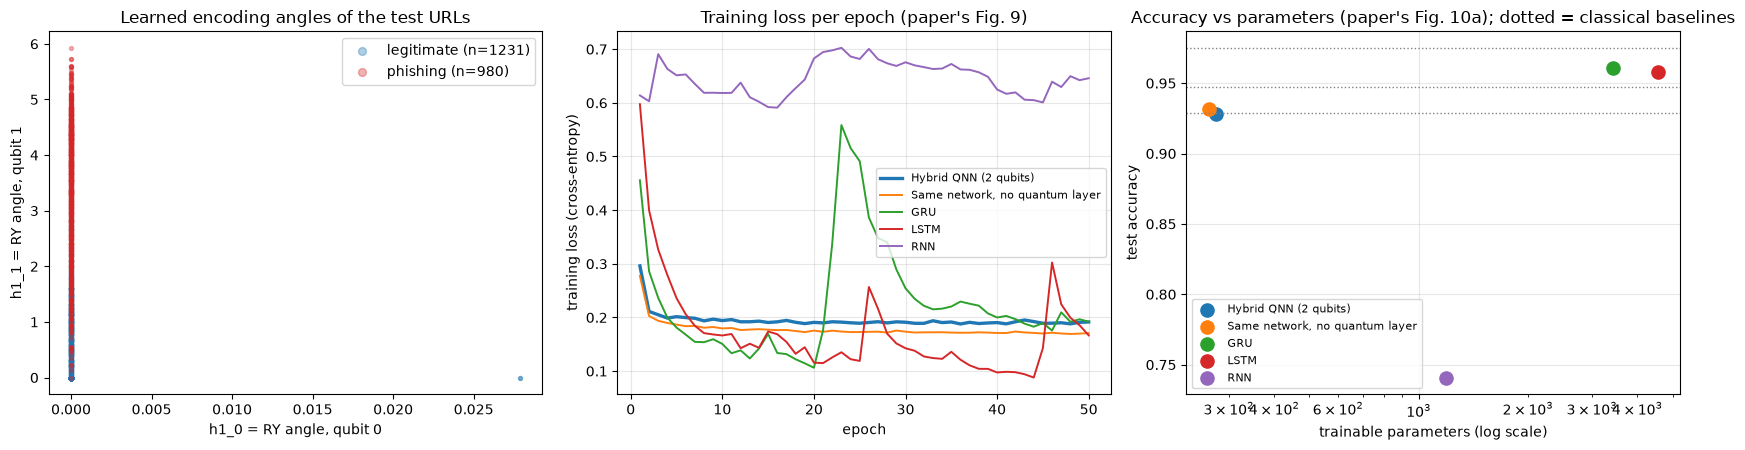

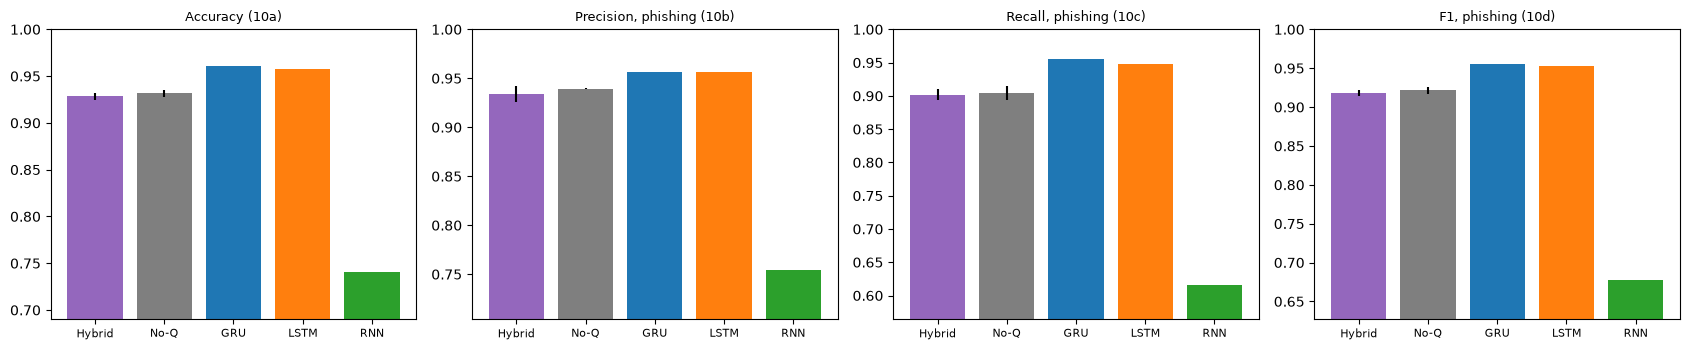

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
Hn = H_te.numpy()
for c in (0, 1):
    mm = y_te == c
    axes[0].scatter(Hn[mm, 0], Hn[mm, 1], s=8, alpha=0.35, c=cols[c], label=f"{names[c]} (n={mm.sum()})")
axes[0].set_xlabel("h1_0 = RY angle, qubit 0"); axes[0].set_ylabel("h1_1 = RY angle, qubit 1"); axes[0].set_title("Learned encoding angles of the test URLs"); axes[0].legend(markerscale=2)
order = [HY, NQ, "GRU", "LSTM", "RNN"]
for v in order:
    L_ = np.mean([runs[(v, s)]["hist"]["train_loss"].values for s in SEEDS if (v, s) in runs], axis=0)
    axes[1].plot(np.arange(1, EPOCHS + 1), L_, lw=2.4 if v == HY else 1.4, label=v)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("training loss (cross-entropy)"); axes[1].set_title("Training loss per epoch (paper's Fig. 9)"); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
g_ = net_df.groupby("model")[["params", "acc"]].mean().loc[order]
for v in order:
    axes[2].scatter(g_.loc[v, "params"], g_.loc[v, "acc"], s=90, label=v)
for cn in base_df.model.unique():
    axes[2].axhline(base_df[base_df.model == cn].acc.mean(), ls=":", lw=1, color="gray")
axes[2].set_xscale("log"); axes[2].set_xlabel("trainable parameters (log scale)"); axes[2].set_ylabel("test accuracy")
axes[2].set_title("Accuracy vs parameters (paper's Fig. 10a); dotted = classical baselines"); axes[2].legend(fontsize=8); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, col, ttl in zip(axes, ["acc", "p_ph", "r_ph", "f1_ph"], ["Accuracy (10a)", "Precision, phishing (10b)", "Recall, phishing (10c)", "F1, phishing (10d)"]):
    mu = net_df.groupby("model")[col].mean().loc[order]; sd = net_df.groupby("model")[col].std(ddof=0).loc[order].fillna(0)
    ax.bar(range(5), mu.values, yerr=sd.values, color=["tab:purple", "tab:gray", "tab:blue", "tab:orange", "tab:green"])
    ax.set_xticks(range(5)); ax.set_xticklabels(["Hybrid", "No-Q", "GRU", "LSTM", "RNN"], fontsize=8); ax.set_ylim(max(0.5, mu.min() - 0.05), 1.0); ax.set_title(ttl, fontsize=9)
plt.tight_layout(); plt.show()

## 7. Side by side with the paper

Rule: a number is *reproduced* when it lies within 0.02 (accuracy, F1, AUC) of the paper's value; otherwise *not reached* (we are lower) or *exceeded* (we are higher) with the gap. The paper states 97.3 % accuracy in its abstract and conclusion but 93 % in the results section, and its own confusion matrix gives 92.7 %; all three are shown. Per-class values follow the size-based class mapping explained in section 4. Qualitative claims get a verdict computed from the trained model of the first seed.

In [19]:
hyb = net_df[net_df.model == HY]
def mean_std(col, d=hyb): return d[col].mean(), (d[col].std(ddof=0) if len(d) > 1 else 0.0)
paper = [  # (claim, paper value, notebook column)
    ("Accuracy (abstract / conclusion: 97.3 %)", 0.973, "acc"),
    ("Accuracy (results text: 93 %)", 0.93, "acc"),
    ("Accuracy from Fig. 7 (2050/2211)", 2050 / 2211, "acc"),
    ("Macro-average F1 (Fig. 6)", 0.93, "macro_f1"),
    ("F1 of paper's class 0 = our phishing (Fig. 6)", 0.91, "f1_ph"),
    ("F1 of paper's class 1 = our legitimate (Fig. 6)", 0.94, "f1_lg"),
    ("AUC (Fig. 8)", 0.9768, "auc"),
]
out = []
for claim, pv, col in paper:
    m, sd = mean_std(col); gap = m - pv
    out.append(dict(claim=claim, paper=round(pv, 4), notebook=f"{m:.4f} +- {sd:.4f}", gap=round(gap, 4),
                    verdict="reproduced" if abs(gap) <= 0.02 else ("exceeded" if gap > 0 else "not reached")))
m_err, sd_err = mean_std("errors")
out.append(dict(claim="Misclassified of 2,211 test URLs (Fig. 7: 98 + 63)", paper=161, notebook=f"{m_err:.1f} +- {sd_err:.1f}",
                gap=round(m_err - 161, 1), verdict="reproduced" if abs(m_err - 161) <= 0.02 * 2211 else ("exceeded (fewer errors)" if m_err < 161 else "not reached")))
out.append(dict(claim="Circuit size: 2 qubits (Table 1)", paper=2, notebook=N_QUBITS, gap=0, verdict="reproduced"))

# efficiency / convergence claims (Figs. 9, 10) against our GRU / LSTM / RNN
pp = net_df.groupby("model")["params"].first()
fewest = pp[HY] < min(pp["GRU"], pp["LSTM"], pp["RNN"])
out.append(dict(claim="Fewest trainable parameters of the four models (Fig. 10, abstract)", paper="yes",
                notebook=f"hybrid {pp[HY]} vs GRU {pp['GRU']}, LSTM {pp['LSTM']}, RNN {pp['RNN']}", gap="",
                verdict="reproduced" if fewest else "not reached"))
tl = {v: np.mean([runs[(v, s)]["hist"]["train_loss"].values for s in SEEDS if (v, s) in runs], axis=0) for v in order}
early = slice(0, max(3, EPOCHS // 5))
lower = all(tl[HY][early].mean() < tl[k][early].mean() for k in ("GRU", "LSTM", "RNN"))
lower_end = all(tl[HY][-1] < tl[k][-1] for k in ("GRU", "LSTM", "RNN"))
out.append(dict(claim="Lower training loss than GRU/LSTM/RNN in the first epochs (Fig. 9)", paper="yes",
                notebook=f"early mean loss: hybrid {tl[HY][early].mean():.3f} vs " + ", ".join(f"{k} {tl[k][early].mean():.3f}" for k in ("GRU", "LSTM", "RNN")),
                gap="", verdict="reproduced" if lower else "not reached"))
out.append(dict(claim="Lower final training loss than GRU/LSTM/RNN (Fig. 9)", paper="yes",
                notebook=f"final loss: hybrid {tl[HY][-1]:.3f} vs " + ", ".join(f"{k} {tl[k][-1]:.3f}" for k in ("GRU", "LSTM", "RNN")),
                gap="", verdict="reproduced" if lower_end else "not reached"))
acc_m = net_df.groupby("model")["acc"].mean(); f1_m = net_df.groupby("model")["f1_ph"].mean()
best_acc = acc_m[HY] >= max(acc_m["GRU"], acc_m["LSTM"], acc_m["RNN"]) - 1e-12
best_f1 = f1_m[HY] >= max(f1_m["GRU"], f1_m["LSTM"], f1_m["RNN"]) - 1e-12
out.append(dict(claim="Highest accuracy of the four models (Fig. 10a)", paper="yes",
                notebook=f"hybrid {acc_m[HY]:.4f} vs GRU {acc_m['GRU']:.4f}, LSTM {acc_m['LSTM']:.4f}, RNN {acc_m['RNN']:.4f}", gap="",
                verdict="reproduced" if best_acc else "not reached"))
out.append(dict(claim="Highest F1 (phishing) of the four models (Fig. 10d)", paper="yes",
                notebook=f"hybrid {f1_m[HY]:.4f} vs GRU {f1_m['GRU']:.4f}, LSTM {f1_m['LSTM']:.4f}, RNN {f1_m['RNN']:.4f}", gap="",
                verdict="reproduced" if best_f1 else "not reached"))
# qualitative claims on the trained circuit (Figs. 4-5), judged on the first seed
med = np.median(Z, 0)
out.append(dict(claim="Qubit 0: <Z> concentrated near +1 (Fig. 5)", paper="median near +1", notebook=f"median <Z0> = {med[0]:.2f}", gap="",
                verdict="reproduced" if med[0] > 0.8 else "not reached (training-dependent detail)"))
out.append(dict(claim="Qubit 1: broad spread incl. values near -1 (Fig. 5)", paper="broad, symmetric", notebook=f"<Z1> range [{Z[:,1].min():.2f}, {Z[:,1].max():.2f}], std {Z[:,1].std():.2f}", gap="",
                verdict="reproduced" if (Z[:, 1].min() < -0.8 and Z[:, 1].std() > 0.3) else "not reached (training-dependent detail)"))
cmp_df = pd.DataFrame(out)
pd.set_option("display.max_colwidth", 140, "display.width", 250)
display(cmp_df)
print("verdict counts:", cmp_df.verdict.str.split(" ").str[0].value_counts().to_dict())

,claim,paper,notebook,gap,verdict
0,Accuracy (abstract / conclusion: 97.3 %),0.973,0.9282 +- 0.0034,-0.0448,not reached
1,Accuracy (results text: 93 %),0.93,0.9282 +- 0.0034,-0.0018,reproduced
2,Accuracy from Fig. 7 (2050/2211),0.9272,0.9282 +- 0.0034,0.0011,reproduced
3,Macro-average F1 (Fig. 6),0.93,0.9270 +- 0.0035,-0.003,reproduced
4,F1 of paper's class 0 = our phishing (Fig. 6),0.91,0.9176 +- 0.0039,0.0076,reproduced
5,F1 of paper's class 1 = our legitimate (Fig. 6),0.94,0.9364 +- 0.0031,-0.0036,reproduced
6,AUC (Fig. 8),0.9768,0.9773 +- 0.0006,0.0005,reproduced
7,"Misclassified of 2,211 test URLs (Fig. 7: 98 + 63)",161,158.7 +- 7.5,-2.3,reproduced
8,Circuit size: 2 qubits (Table 1),2,2,0,reproduced
9,"Fewest trainable parameters of the four models (Fig. 10, abstract)",yes,"hybrid 276 vs GRU 3426, LSTM 4546, RNN 1186",,reproduced


verdict counts: {'reproduced': 11, 'not': 5}


### Does the quantum layer matter?

The paper contains no ablation. We train the identical network with the circuit removed (the 2-number encoder output goes straight into the head) and compare it with the hybrid network and with the classical baselines on the same split.

In [20]:
abl = net_df.groupby("model")[["params", "acc", "weighted_f1", "macro_f1", "auc", "errors", "seconds"]].agg(["mean", "std"]).round(4)
display(abl.loc[[HY, NQ]])
d = net_df[net_df.model == HY].set_index("seed")["acc"] - net_df[net_df.model == NQ].set_index("seed")["acc"]
print("accuracy gain of the quantum layer per seed (hybrid minus no-quantum):", d.round(4).to_dict(), "| mean", round(d.mean(), 4))
print("best classical baseline on the 30 raw features:", base_df.groupby("model").acc.mean().round(4).idxmax(), round(base_df.groupby("model").acc.mean().max(), 4))

params          acc         weighted_f1         macro_f1             auc            errors            seconds         
                                 mean  std    mean     std        mean     std     mean     std    mean     std      mean      std      mean      std
model                                                                                                                                                
Hybrid QNN (2 qubits)           276.0  0.0  0.9282  0.0042      0.9281  0.0042   0.9270  0.0042  0.9773  0.0008  158.6667   9.2376  359.7856  98.1731
Same network, no quantum layer  264.0  0.0  0.9317  0.0048      0.9315  0.0048   0.9305  0.0050  0.9807  0.0003  151.0000  10.5357   79.1494  34.4186

accuracy gain of the quantum layer per seed (hybrid minus no-quantum):

 {42: -0.0109, 43: -0.0054, 44: 0.0059} | mean -0.0035
best classical baseline on the 30 raw features: RandomForest (300 trees) 0.9751


## 8. Reading the paper critically

*(Numbers quoted below come from the executed full run in this notebook: 3 seeds for the hybrid network and the no-quantum ablation, 1 seed for GRU / LSTM / RNN.)*

* **Three different accuracies in one paper.** The abstract, the contributions list and the conclusion state 97.3 %. The results section states 93 %, and the confusion matrix of Fig. 7 gives (858 + 1,192) / 2,211 = 92.7 %. Our run reaches about 92.8 % (three seeds, 92.4 to 93.3 %), so the 93 % and the matrix are reproduced and the headline 97.3 % is not: we find nothing in the described method that gets there (see the baselines below, where only tree and recurrent models pass 95 %).
* **The class names look swapped.** In Fig. 7 class 0 ("Safe") has 956 test URLs and class 1 ("Phishing") 1,255. The UCI file has 4,898 phishing and 6,157 legitimate sites, i.e. about 980 and 1,231 in a 20 % test set, and the paper's 55.7 % "phishing" share is the *legitimate* share of the file. The paper's "Safe" class is therefore probably the real phishing class. Accuracy, macro averages, AUC and error counts do not depend on this; the per-class rows of section 7 follow the size-based mapping.
* **Half of the data are copies.** The UCI file has 5,206 exact duplicate rows out of 11,055 (printed in section 1). A random split puts copies of the same URL vector on both sides, which flatters every model, quantum or not, and probably explains why a random forest memorises its way to 97.5 %.
* **The two-number bottleneck is the limit, not the circuit.** The architecture squeezes the 30 features into 2 numbers before anything quantum happens. A plain logistic regression on all 30 features reaches 92.9 %, exactly the accuracy of the hybrid network (92.8 %); SVC (RBF) reaches 94.7 % and a random forest 97.5 %. The paper gives no classical reference, so the 93 % looks like a result for the 2-unit bottleneck rather than for the quantum layer.
* **The quantum layer does not help.** The paper contains no ablation. The identical network with the circuit removed (the 2-number encoder output goes straight into the head) reaches 93.2 % against 92.8 % for the hybrid; the difference (mean -0.35 points, seed-by-seed -1.1, -0.5, +0.6) is within seed noise. Two qubits add 12 weights to a network that already has 264; the exact simulation costs about five times the wall-clock time of the classical network in our run (about 360 s against 79 s per training run), which sits badly with the "lightweight, resource-constrained deployment" claim.
* **The comparison with GRU, LSTM and RNN is not like for like and does not hold up.** The 30 features are a flat vector, not a sequence, so reading them as 30 time steps is an odd baseline (the paper does not say how its recurrent models consumed the data). Trained with the paper's own settings (Adam, lr 0.01, batch 32, 50 epochs) on one seed, our GRU and LSTM reach 96.1 % and 95.8 %, above the hybrid network, though their training curves are unstable (loss spikes) and the plain RNN fails (74 %). The claim that the hybrid has the fewest trainable parameters (276 against 1,186 to 4,546) is true by construction; the claims of the highest accuracy, precision and F1 are not reproduced. The faster early convergence of Fig. 9 holds only narrowly (mean loss 0.210 against 0.215 for the GRU over the first epochs) and the final training loss is not lower than that of the LSTM. These comparisons use one seed for the recurrent models and should be read as indicative.
* **Figs. 4-5 are training-dependent.** The paper reports `<Z0>` concentrated near +1 and a broad `<Z1>`; in our run the median `<Z0>` is 0.19 and `<Z1>` is broad (std 0.49). Where the output sits depends on the unstated initial weights, the number of layers L and the encoder; it carries no evidence about the method.
* **Bloch spheres are not an interpretability result.** Because the CNOTs entangle the two qubits, each reduced state is mixed (mean Bloch-vector length 0.94 in our run, below 1). The orientation of single-qubit vectors says little about class separability, and no quantitative interpretability measure is given.
* **"Robust" and "deployable" are not tested.** Everything is exact simulation: no shot noise, no hardware noise model, no adversarial or drifting URLs, no real device; the paper itself lists this as a limitation.
* **Missing details.** The number of layers L, the exact CNOT pattern, the hidden widths of the post-quantum layers, the data split and its seed, the precise recurrent baselines and the stopping rule are not given. The Zenodo code (DOI 10.5281/zenodo.17364368) could settle these; this notebook was deliberately written from the paper text only, so every such choice is marked `# CHOICE:` above.

## 9. Exercises

1. **Depth.** Change `N_LAYERS` to 1, 3, 5 and 8 and plot test accuracy against depth. Does a deeper circuit help, and does the fast simulator keep its equality with the QNode (the assertion cell)?
2. **Ablation done properly.** Replace the circuit by a classical layer with the same number of outputs and parameters (`nn.Linear(2, 2)` followed by `tanh`) and train with the same budget. Is the hybrid better than a classical network with an equal-size bottleneck?
3. **Wider bottleneck.** The 30 -> 2 encoder is a severe bottleneck. Use 4 qubits (rewrite `fast_out` or call the QNode) and 4 encoder outputs. How much of the gap to Random Forest closes?
4. **Honest split.** Remove exact duplicate rows before splitting (`raw.drop_duplicates()`) and repeat the notebook. How much of the accuracy was due to copies on both sides of the split?
5. **Noise.** Switch the device to `qml.device("default.mixed", wires=2)` and add `qml.DepolarizingChannel(0.02, wires=i)` after each CNOT pair, evaluate the trained model with that noise, and discuss whether "resource-constrained deployment" claims survive noisy hardware.